# Supervised Learning with Scikit-learn
**ML Month · SOAI Béjaïa workshop**: regression and classification, hands-on.

### How to use this notebook
- Each section matches one slide of the deck, in the same order. The slide number is in the section title.
- Run the cells **from top to bottom**. Later cells reuse variables created earlier.
- Every step has a short *Why?* note, because knowing why a step exists is what lets you reuse it on new problems.
- Look for the **Your turn** cells. They are small exercises to try yourself.

| Slides | Section | What you will do |
|---|---|---|
| 3 | 1. The pipeline | Build a model in six steps |
| 4 | 2. Regression | Recognize a continuous target |
| 5 | 3. Multiple linear regression | Read the weights |
| 6 | 4. How it learns | Residuals and MSE |
| 7 | 5. Evaluating regression | MAE, RMSE, R² |
| 8 | 6. Logistic regression | Sigmoid and threshold |
| 9 | 7. K-Nearest Neighbors | Neighbors, scaling, choosing K |
| 10 | 8. Confusion matrix | TP, FP, FN, TN |
| 11 | 9. Classification metrics | Accuracy, precision, recall, F1 |
| agenda part 4 | 10. Overfitting and underfitting | Train vs test gap |

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyRegressor
from sklearn.datasets import make_blobs, load_breast_cancer
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score,
                             f1_score, classification_report)

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3})
print("Setup done")

Setup done


---
## 1. The pipeline: six steps to build a model *(slide 3)*

Every supervised model follows the same six steps. We will walk through them once on a house-price problem.

**The data.** We create a small synthetic dataset using the exact formula from slide 5:

`price = 2,500·size + 8,000·rooms − 1,200·age + 15,000 + noise`

*Why synthetic?* Because we **know the true weights**. Later we can check whether the model discovers them, which is rare with real data.

In [ ]:
rng = np.random.default_rng(42)
n = 300

size = rng.uniform(40, 200, n)        # square meters
rooms = rng.integers(1, 7, n)         # 1 to 6 rooms
age = rng.integers(0, 41, n)          # 0 to 40 years
noise = rng.normal(0, 15_000, n)      # things the features can't explain

price = 2500 * size + 8000 * rooms - 1200 * age + 15_000 + noise

df = pd.DataFrame({"size": size.round(1), "rooms": rooms, "age": age, "price": price.round(0)})
df.head()

,size,rooms,age,price
0,163.8,4,0,475302.0
1,110.2,5,1,325564.0
2,177.4,5,8,494291.0
3,151.6,1,36,322598.0
4,55.1,5,18,153726.0


In [ ]:
df.describe().round(1)

,size,rooms,age,price
count,300.0,300.0,300.0,300.0
mean,117.9,3.6,20.1,313196.4
std,46.5,1.8,11.3,118223.1
min,41.2,1.0,0.0,98807.0
25%,76.4,2.0,11.0,209776.5
50%,116.6,4.0,20.0,307297.0
75%,160.2,5.0,29.0,414428.2
max,198.8,6.0,40.0,547124.0


### Step 1: Separate X and y
**Why?** The model has to learn the link between inputs and answer, so we must tell it which columns are which. Features go in (`X`), the target comes out (`y`).

In [111]:
X = df[["size", "rooms", "age"]]   # features: capital X because it is a table
y = df["price"]                    # target: lowercase y because it is one column

print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (300, 3) | y shape: (300,)


### Step 2: Train-test split
**Why?** The test set is the *fair exam*. The model never sees it while learning, so its score on it tells us how the model behaves on new data. `random_state` makes the split reproducible.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (240, 3) | Test: (60, 3)


### Step 3: Initialize the model
**Why?** Choosing the algorithm is separate from learning. At this point the model is empty, and swapping it for another algorithm later changes only this line.

In [ ]:
model = LinearRegression()
model

LinearRegression()

### Step 4: `fit()`, which means train
**Why?** This is where the learning happens: the model finds the weights that fit the training data best.

In [113]:
model.fit(X_train, y_train)
print("Training done")

Training done


### Step 5: `predict()`
**Why?** This is what the model is for. We predict on the **test set** first so that we can check its work.

In [ ]:
y_pred = model.predict(X_test)

pd.DataFrame({"actual": y_test.values[:5], "predicted": y_pred[:5].round(0)})

,actual,predicted
0,212591.0,213086.0
1,267489.0,269047.0
2,138307.0,154410.0
3,321905.0,339354.0
4,321186.0,322809.0


### Step 6: Evaluate
**Why?** A model we haven't measured is just a guess. We compare predictions with the truth (the metrics are explained in section 5).

In [ ]:
print(f"MAE : {mean_absolute_error(y_test, y_pred):,.0f}")
print(f"R²  : {r2_score(y_test, y_pred):.3f}")

MAE : 12,567
R²  : 0.982


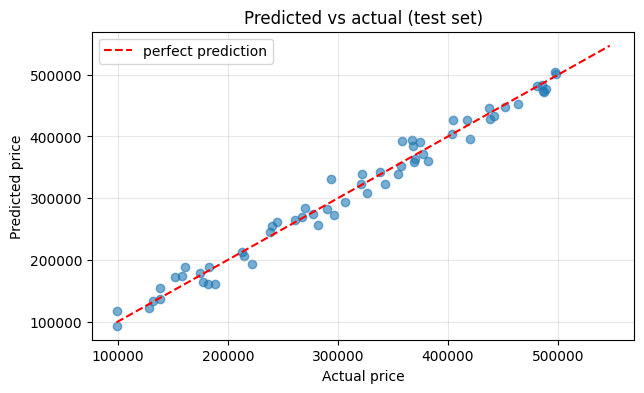

In [ ]:
plt.scatter(y_test, y_pred, alpha=0.6)
lims = [y.min(), y.max()]
plt.plot(lims, lims, "r--", label="perfect prediction")
plt.xlabel("Actual price"); plt.ylabel("Predicted price"); plt.legend()
plt.title("Predicted vs actual (test set)")
plt.show()

Points close to the red dashed line are good predictions. **The same pattern (initialize, `fit`, `predict`) works for every Scikit-learn model.**

---
## 2. Regression: predicting a number *(slide 4)*

**Key idea:** the target `y` is **continuous**. It can take any value in a range.

*Why does this matter?* The type of target decides which model and which metric you use. Always ask first: what kind of target do I have?

Target dtype: float64
Distinct values: 300 out of 300 rows


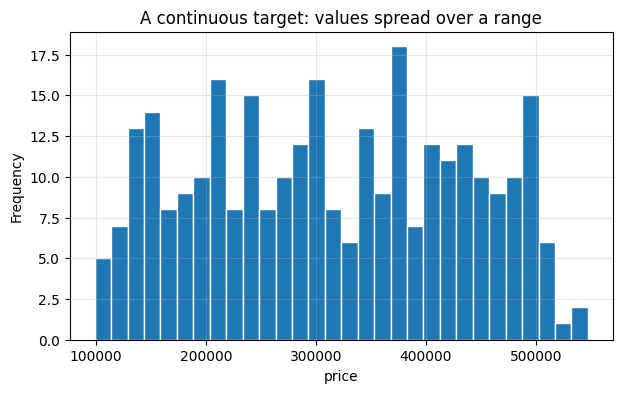

In [ ]:
print("Target dtype:", y.dtype)
print("Distinct values:", y.nunique(), "out of", len(y), "rows")

y.plot(kind="hist", bins=30, edgecolor="white")
plt.xlabel("price"); plt.title("A continuous target: values spread over a range")
plt.show()

**Your turn.** For each target, decide: regression or classification?
1. Tomorrow's temperature in degrees
2. Whether an email is spam
3. A person's salary
4. Whether a student passes or fails

*Answers: 1 and 3 are regression (a number on a scale). 2 and 4 are classification (a category).*

---
## 3. Multiple linear regression: several features, one weight each *(slide 5)*

`y = w1·x1 + w2·x2 + … + b`

- `model.coef_` holds the weights `w`
- `model.intercept_` holds the bias `b`

*Why look at them?* Linear regression is readable: you get a prediction **and** an explanation of why.

In [ ]:
weights = pd.Series(model.coef_, index=X.columns)
print("Learned weights:\n", weights.round(1))
print("\nLearned bias b:", round(model.intercept_))

print("\nTrue weights used to create the data: size 2500, rooms 8000, age -1200, b 15000")

Learned weights:
 size     2495.3
rooms    7934.4
age     -1250.5
dtype: float64

Learned bias b: 15782

True weights used to create the data: size 2500, rooms 8000, age -1200, b 15000


The learned weights are close to the true ones. They are not identical because of the noise we added.

**Reading them:** one extra unit of `size` adds about 2,500 to the price, and one extra year of `age` *removes* about 1,200. The age weight is negative because older houses are cheaper.

### Compute one prediction by hand (the worked example from the slide)
A house with size 100, 3 rooms, 10 years old.

In [ ]:
house = pd.DataFrame({"size": [100], "rooms": [3], "age": [10]})

by_hand = sum(w * x for w, x in zip(model.coef_, house.iloc[0])) + model.intercept_
by_model = model.predict(house)[0]
true_formula = 2500 * 100 + 8000 * 3 - 1200 * 10 + 15_000

print(f"By hand with learned weights : {by_hand:,.0f}")
print(f"model.predict()              : {by_model:,.0f}")
print(f"Slide formula (true weights) : {true_formula:,.0f}")

By hand with learned weights : 276,605
model.predict()              : 276,605
Slide formula (true weights) : 277,000


**Caution when comparing weights.** A weight of 8,000 for `rooms` is not automatically "more important" than 2,500 for `size`, because the features are in different units. To compare fairly, standardize the features first.

In [ ]:
scaled_model = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
std_weights = pd.Series(scaled_model[-1].coef_, index=X.columns)

print("Weights after standardization (effect of +1 standard deviation):")
print(std_weights.round(0))

Weights after standardization (effect of +1 standard deviation):
size     116374.0
rooms     13892.0
age      -13766.0
dtype: float64


**Your turn.** Which feature has the strongest effect once everything is on the same scale? Does the answer match your first guess from the raw weights?

---
## 4. How does it learn? The best line has the smallest error *(slide 6)*

- **Residual** = actual y − predicted y (the model's mistake on one point)
- **MSE** = mean(residual²)

We use a single feature (`size`) and 12 points so that the picture is easy to read.

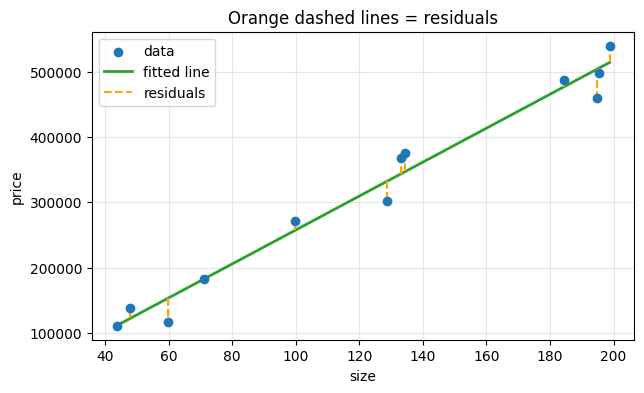

In [ ]:
small = df.sample(12, random_state=3).sort_values("size")
xs = small[["size"]]
ys = small["price"]

line = LinearRegression().fit(xs, ys)
pred = line.predict(xs)
residuals = ys.values - pred

plt.scatter(xs, ys, color="tab:blue", zorder=3, label="data")
plt.plot(xs, pred, color="tab:green", lw=2, label="fitted line")
plt.vlines(xs["size"], pred, ys, colors="orange", linestyles="dashed", label="residuals")
plt.xlabel("size"); plt.ylabel("price"); plt.legend()
plt.title("Orange dashed lines = residuals")
plt.show()

### Why do we square the residuals?
1. **Signs would cancel.** Positive and negative mistakes average out to about zero, which would make any line look perfect.
2. **Big mistakes count more.** An error of 20 becomes 400, which is four times more than an error of 10 (100).

In [ ]:
print("Mean of raw residuals :", round(residuals.mean(), 6), " (cancels to ~0)")
print("Mean of squared resid.:", f"{np.mean(residuals ** 2):,.0f}", " (this is the MSE)")
print("sklearn MSE           :", f"{mean_squared_error(ys, pred):,.0f}")

Mean of raw residuals : 0.0  (cancels to ~0)
Mean of squared resid.: 576,720,693  (this is the MSE)
sklearn MSE           : 576,720,693


### `fit()` searches for the weights that make MSE as small as possible
To see this, we try many slopes and measure the MSE of each. For every slope we use the best intercept for it (the mean of `y − slope·x`).

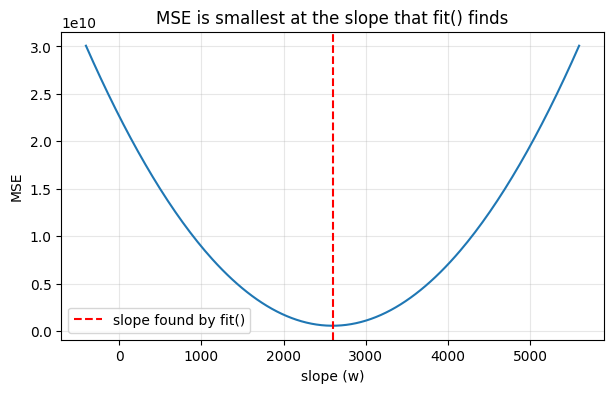

In [ ]:
slopes = np.linspace(line.coef_[0] - 3000, line.coef_[0] + 3000, 200)
mses = []
for w in slopes:
    b = np.mean(ys.values - w * xs["size"].values)
    mses.append(np.mean((ys.values - (w * xs["size"].values + b)) ** 2))

plt.plot(slopes, mses)
plt.axvline(line.coef_[0], color="red", ls="--", label="slope found by fit()")
plt.xlabel("slope (w)"); plt.ylabel("MSE"); plt.legend()
plt.title("MSE is smallest at the slope that fit() finds")
plt.show()

The curve has one lowest point, and `fit()` lands exactly there. **Learning means minimizing an error.** You will see this idea in almost every model.

---
## 5. Evaluating regression: how good are the predictions? *(slide 7)*

| Metric | Question it answers | Units |
|---|---|---|
| **MAE** | How far off am I on average? | same as y |
| **RMSE** | Do I make big mistakes? | same as y |
| **R²** | How much better am I than always guessing the average? | none |

*Why several?* No single number tells the whole story.

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)              # square root brings MSE back to the units of y
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:,.0f}   -> on average we are off by this much")
print(f"RMSE : {rmse:,.0f}   -> like MAE, but punishes big errors more")
print(f"R²   : {r2:.3f}      -> share of the variation in price explained")

MAE  : 12,567   -> on average we are off by this much
RMSE : 15,499   -> like MAE, but punishes big errors more
R²   : 0.982      -> share of the variation in price explained


**Tip:** if RMSE is much bigger than MAE, a few large errors are hiding in the predictions.

### Understanding R²: compare with a lazy model
A lazy model ignores all features and **always predicts the average price**. R² asks how much better our model is than that baseline:

`R² = 1 − (your model's squared error ÷ lazy model's squared error)`

First, the small example from the explanation: real prices 10, 20, 30.

In [ ]:
real = np.array([10, 20, 30])
yours = np.array([11, 19, 31])
lazy = np.full(3, real.mean())          # always predicts 20

your_err = np.sum((real - yours) ** 2)  # 1 + 1 + 1 = 3
lazy_err = np.sum((real - lazy) ** 2)   # 100 + 0 + 100 = 200

print("Your error:", your_err, "| Lazy error:", lazy_err)
print("R² by hand :", round(1 - your_err / lazy_err, 3))
print("R² sklearn :", round(r2_score(real, yours), 3))

Your error: 3 | Lazy error: 200.0
R² by hand : 0.985
R² sklearn : 0.985


Now the same idea on our house data, using Scikit-learn's `DummyRegressor` as the lazy model.

In [ ]:
lazy_model = DummyRegressor(strategy="mean").fit(X_train, y_train)

print(f"Lazy model R² on test : {r2_score(y_test, lazy_model.predict(X_test)):.3f}   (0 means no better than the average)")
print(f"Our model R² on test  : {r2_score(y_test, y_pred):.3f}")

Lazy model R² on test : -0.001   (0 means no better than the average)
Our model R² on test  : 0.982


| R² | Meaning |
|---|---|
| 1.0 | Perfect predictions |
| 0.85 | The model explains about 85% of the variation |
| 0 | No better than predicting the average |
| negative | Worse than predicting the average, so something is wrong |

### The golden rule: always measure on the test set
Compare the score on data the model has seen with the score on data it has not.

In [ ]:
print(f"R² on TRAIN set: {r2_score(y_train, model.predict(X_train)):.3f}")
print(f"R² on TEST set : {r2_score(y_test, model.predict(X_test)):.3f}")

R² on TRAIN set: 0.983
R² on TEST set : 0.982


Here the two are close, which is a healthy sign. In section 10 you will see what it looks like when they are far apart.

---
## 6. Logistic regression: from a line to a probability *(slide 8)*

Despite its name, this is a **classification** model.

1. `z = w·x + b` (the same weighted sum as before; it can be any number)
2. `p = 1 / (1 + e^(−z))` (the **sigmoid** squeezes z into the range 0 to 1)
3. If `p ≥ 0.5` predict class 1, otherwise class 0

**Example:** hours studied → probability of passing the exam (synthetic data).

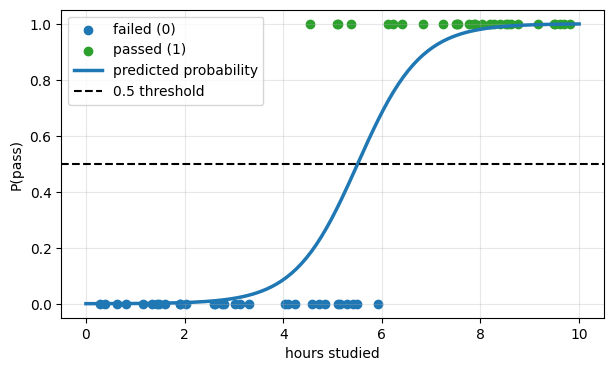

In [ ]:
rng = np.random.default_rng(1)
hours = rng.uniform(0, 10, 60)
p_true = 1 / (1 + np.exp(-1.3 * (hours - 5)))
passed = (rng.random(60) < p_true).astype(int)      # 0 = fail, 1 = pass

X_h = hours.reshape(-1, 1)
clf = LogisticRegression().fit(X_h, passed)

grid = np.linspace(0, 10, 200).reshape(-1, 1)
prob = clf.predict_proba(grid)[:, 1]

plt.scatter(hours[passed == 0], passed[passed == 0], color="tab:blue", label="failed (0)")
plt.scatter(hours[passed == 1], passed[passed == 1], color="tab:green", label="passed (1)")
plt.plot(grid, prob, color="tab:blue", lw=2.5, label="predicted probability")
plt.axhline(0.5, color="k", ls="--", label="0.5 threshold")
plt.xlabel("hours studied"); plt.ylabel("P(pass)"); plt.legend()
plt.show()

### Why not just use linear regression for this?
A straight line goes **below 0 and above 1**, and a "probability" of 1.4 or −0.3 means nothing.

In [ ]:
lin = LinearRegression().fit(X_h, passed)
line_pred = lin.predict(grid)
print("Linear regression output range:", line_pred.min().round(2), "to", line_pred.max().round(2))
print("Logistic regression output range:", prob.min().round(2), "to", prob.max().round(2))

Linear regression output range: -0.29 to 1.17
Logistic regression output range: 0.0 to 1.0


### Check the sigmoid by hand
We compute `z` and `p` ourselves for a student who studied 6 hours, then compare with Scikit-learn.

In [ ]:
w, b = clf.coef_[0, 0], clf.intercept_[0]
z = w * 6 + b
p_manual = 1 / (1 + np.exp(-z))

print(f"w = {w:.2f}, b = {b:.2f}, z = {z:.2f}")
print(f"p by hand      : {p_manual:.4f}")
print(f"predict_proba  : {clf.predict_proba([[6]])[0, 1]:.4f}")
print("predict (class):", clf.predict([[6]])[0])

w = 1.57, b = -8.64, z = 0.77
p by hand      : 0.6827
predict_proba  : 0.6827
predict (class): 1


`predict()` gives the **class**, and `predict_proba()` gives the **probability**. The probability tells you how sure the model is: 0.51 and 0.99 are both "pass", but they are very different levels of confidence.

### The 0.5 threshold is only a default
**Why change it?** Lowering the threshold predicts "pass" more often, so you catch more true cases but make more false alarms.

In [ ]:
probs = clf.predict_proba(X_h)[:, 1]
for t in [0.3, 0.5, 0.7]:
    print(f"threshold {t}: predicted 'pass' for {(probs >= t).sum()} of {len(probs)} students")

threshold 0.3: predicted 'pass' for 34 of 60 students
threshold 0.5: predicted 'pass' for 26 of 60 students
threshold 0.7: predicted 'pass' for 25 of 60 students


**Your turn.** Change the `1.3` in `p_true` to a smaller number such as `0.5`. The real relationship becomes weaker. What happens to the shape of the curve?

---
## 7. K-Nearest Neighbors: ask the closest neighbors *(slide 9)*

1. Choose a value for K
2. Find the K closest points to the new sample
3. The majority class among them wins

### The idea on a small 2D dataset

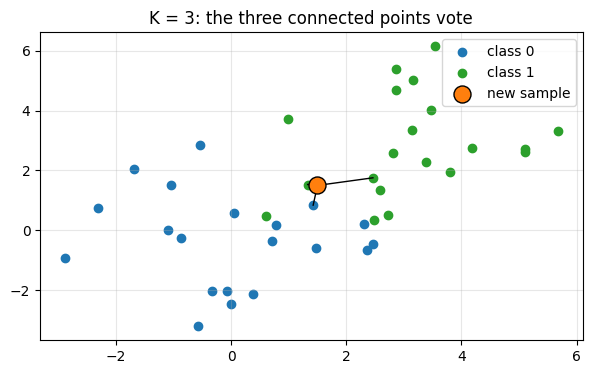

Classes of the 3 nearest neighbors: [1 0 1]
Prediction (majority vote): 1


In [ ]:
Xb, yb = make_blobs(n_samples=40, centers=[[0, 0], [3, 3]], cluster_std=1.4, random_state=7)

knn = KNeighborsClassifier(n_neighbors=3).fit(Xb, yb)
new = np.array([[1.5, 1.5]])
dist, idx = knn.kneighbors(new)

plt.scatter(Xb[yb == 0, 0], Xb[yb == 0, 1], color="tab:blue", label="class 0")
plt.scatter(Xb[yb == 1, 0], Xb[yb == 1, 1], color="tab:green", label="class 1")
plt.scatter(*new[0], color="tab:orange", s=150, edgecolor="k", zorder=5, label="new sample")
for i in idx[0]:
    plt.plot([new[0, 0], Xb[i, 0]], [new[0, 1], Xb[i, 1]], color="k", lw=1)
plt.legend(); plt.title("K = 3: the three connected points vote")
plt.show()

print("Classes of the 3 nearest neighbors:", yb[idx[0]])
print("Prediction (majority vote):", knn.predict(new)[0])

### Choosing K: small K follows the noise, large K gets too smooth
We draw the decision boundary for three values of K.
*Why look at boundaries?* They show overfitting and underfitting directly: K = 1 draws a jagged, noisy boundary, and a very large K draws an over-smooth one.

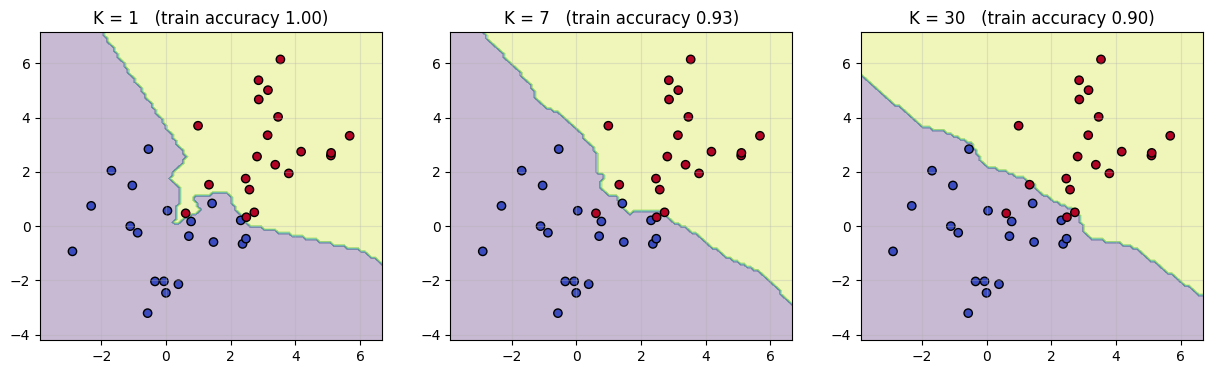

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k in zip(axes, [1, 7, 30]):
    m = KNeighborsClassifier(n_neighbors=k).fit(Xb, yb)
    DecisionBoundaryDisplay.from_estimator(m, Xb, ax=ax, alpha=0.3, response_method="predict")
    ax.scatter(Xb[:, 0], Xb[:, 1], c=yb, edgecolor="k", cmap="coolwarm")
    ax.set_title(f"K = {k}   (train accuracy {m.score(Xb, yb):.2f})")
plt.show()

### KNN needs scaled features
KNN is built on **distance**. If one feature is measured in thousands and another in decimals, the big one dominates every distance. We use the breast-cancer dataset that ships with Scikit-learn to see the effect.

In [ ]:
data = load_breast_cancer()
Xc = pd.DataFrame(data.data, columns=data.feature_names)
yc = data.target                            # 0 = malignant, 1 = benign

Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.2, random_state=42, stratify=yc)

ranges = Xc.describe().T[["min", "max"]]
print("Feature ranges differ hugely, e.g.:")
print(ranges.loc[["mean area", "mean smoothness"]].round(2))

Feature ranges differ hugely, e.g.:
                    min      max
mean area        143.50  2501.00
mean smoothness    0.05     0.16


In [ ]:
raw = KNeighborsClassifier(n_neighbors=5).fit(Xc_train, yc_train)
scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Xc_train, yc_train)

print(f"KNN without scaling: {raw.score(Xc_test, yc_test):.3f}")
print(f"KNN with scaling   : {scaled.score(Xc_test, yc_test):.3f}")

KNN without scaling: 0.912
KNN with scaling   : 0.956


**Why a pipeline?** The scaler is fitted on training data only and then reused on the test data. Scaling the whole dataset before splitting would leak information from the test set into the model.

### Choosing K properly with cross-validation
*Why cross-validation?* A single split can be lucky or unlucky. Averaging over 5 folds gives a steadier estimate.

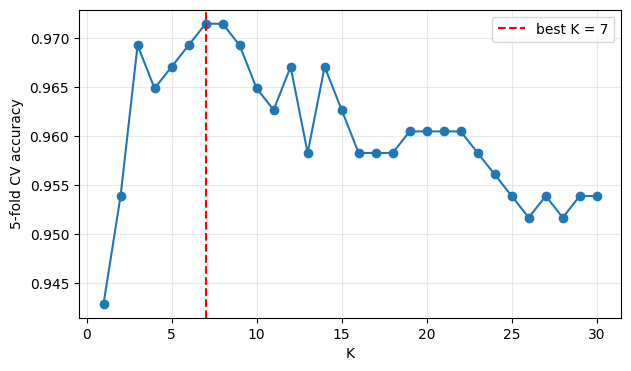

In [ ]:
ks = range(1, 31)
cv_scores = []
for k in ks:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv_scores.append(cross_val_score(pipe, Xc_train, yc_train, cv=5).mean())

best_k = ks[int(np.argmax(cv_scores))]
plt.plot(ks, cv_scores, marker="o")
plt.axvline(best_k, color="red", ls="--", label=f"best K = {best_k}")
plt.xlabel("K"); plt.ylabel("5-fold CV accuracy"); plt.legend()
plt.show()

The same search in one line with `GridSearchCV`. It can also tune the `weights` setting at the same time.

In [ ]:
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
grid = GridSearchCV(pipe,
                    {"kneighborsclassifier__n_neighbors": range(1, 31),
                     "kneighborsclassifier__weights": ["uniform", "distance"]},
                    cv=5)
grid.fit(Xc_train, yc_train)

print("Best parameters:", grid.best_params_)
print(f"CV accuracy    : {grid.best_score_:.3f}")
print(f"Test accuracy  : {grid.score(Xc_test, yc_test):.3f}   (used once, at the very end)")

Best parameters: {'kneighborsclassifier__n_neighbors': 8, 'kneighborsclassifier__weights': 'distance'}
CV accuracy    : 0.974
Test accuracy  : 0.974   (used once, at the very end)


**Rule of thumb:** if several K values score about the same, pick the larger one, because it gives a smoother and usually more robust boundary.

---
## 8. The confusion matrix: a spam filter *(slide 10)*

|  | Predicted: spam | Predicted: not spam |
|---|---|---|
| **Actual: spam** | **TP** spam correctly caught | **FN** spam missed, reaches the inbox |
| **Actual: not spam** | **FP** good email flagged as spam | **TN** good email correctly kept |

**Memory trick:** read each label from right to left. A *false positive* means the model said positive, and that was false.

### The slide's example: 100 emails

In [ ]:
TP, FN, FP, TN = 30, 10, 5, 55

cm_hand = pd.DataFrame([[TP, FN], [FP, TN]],
                       index=["Actual: spam", "Actual: not spam"],
                       columns=["Predicted: spam", "Predicted: not spam"])
cm_hand

,Predicted: spam,Predicted: not spam
Actual: spam,30,10
Actual: not spam,5,55


### On real data: tumor detection
We treat **malignant** as the positive class, because it is the one we must not miss. (In this dataset `0` means malignant, so we flip the labels.)

[[39  3]
 [ 1 71]]


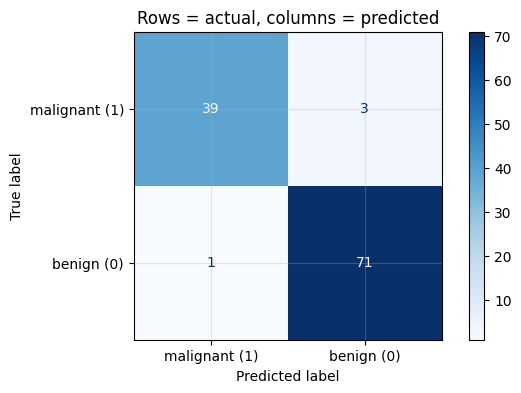

In [ ]:
y_pos = (yc == 0).astype(int)     # 1 = malignant (the case we want to catch), 0 = benign
Xp_train, Xp_test, yp_train, yp_test = train_test_split(Xc, y_pos, test_size=0.2, random_state=42, stratify=y_pos)

clf_cancer = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
clf_cancer.fit(Xp_train, yp_train)
yp_pred = clf_cancer.predict(Xp_test)

# labels=[1, 0] puts the positive class first, so the layout matches the slide: [[TP, FN], [FP, TN]]
cm = confusion_matrix(yp_test, yp_pred, labels=[1, 0])
print(cm)

ConfusionMatrixDisplay(cm, display_labels=["malignant (1)", "benign (0)"]).plot(cmap="Blues")
plt.title("Rows = actual, columns = predicted")
plt.show()

**Warning about the default layout.** Without `labels=[1, 0]`, Scikit-learn orders classes `[0, 1]`, so the top-left cell is **TN** and not TP. Always check the order before reading the numbers.

**Not all mistakes cost the same.** For a spam filter a false positive (a lost good email) is worse. For cancer screening a false negative (a missed sick patient) is much worse.

In [ ]:
tp, fn, fp, tn = cm.ravel()
print(f"TP={tp}  FN={fn}  FP={fp}  TN={tn}")

TP=39  FN=3  FP=1  TN=71


---
## 9. Four ways to score a classifier *(slide 11)*

| Metric | Formula | Question |
|---|---|---|
| Accuracy | (TP + TN) / all | How often is the model right overall? |
| Precision | TP / (TP + FP) | When it says spam, how often is it right? |
| Recall | TP / (TP + FN) | Of all real spam, how much did it catch? |
| F1 | 2·P·R / (P + R) | A balance between precision and recall |

First, by hand on the spam example (TP = 30, FN = 10, FP = 5, TN = 55).

In [ ]:
accuracy = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)

print(f"Accuracy : {accuracy:.3f}")
print(f"Precision: {precision:.3f}   <- trust in the alarm")
print(f"Recall   : {recall:.3f}   <- not missing anything")
print(f"F1       : {f1:.3f}")

Accuracy : 0.850
Precision: 0.857   <- trust in the alarm
Recall   : 0.750   <- not missing anything
F1       : 0.800


### Why accuracy alone can fool you
Imagine only 1 email in 100 is spam, and a lazy model says "not spam" every time.

In [ ]:
y_true = np.array([1] + [0] * 99)     # 1 spam among 100 emails
y_lazy = np.zeros(100, dtype=int)     # always predicts "not spam"

print("Accuracy :", accuracy_score(y_true, y_lazy))
print("Recall   :", recall_score(y_true, y_lazy), "  <- it never catches a single spam")
print("Precision:", precision_score(y_true, y_lazy, zero_division=0))

Accuracy : 0.99
Recall   : 0.0   <- it never catches a single spam
Precision: 0.0


99% accuracy and a useless model. This is why we look at precision and recall, especially when one class is rare.

### All metrics at once on the tumor model

In [ ]:
print(f"Accuracy : {accuracy_score(yp_test, yp_pred):.3f}")
print(f"Precision: {precision_score(yp_test, yp_pred):.3f}")
print(f"Recall   : {recall_score(yp_test, yp_pred):.3f}")
print(f"F1       : {f1_score(yp_test, yp_pred):.3f}")

print()
print(classification_report(yp_test, yp_pred, target_names=["benign", "malignant"]))

Accuracy : 0.965
Precision: 0.975
Recall   : 0.929
F1       : 0.951

              precision    recall  f1-score   support

      benign       0.96      0.99      0.97        72
   malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



### Moving the threshold: the precision and recall tradeoff
Logistic regression gives probabilities, so we can choose our own threshold instead of 0.5.
**Lower threshold → more cases flagged → recall goes up, precision goes down.** The opposite happens with a higher threshold.

In [ ]:
proba = clf_cancer.predict_proba(Xp_test)[:, 1]
rows = []
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred = (proba >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(yp_test, pred, zero_division=0),
                 "recall": recall_score(yp_test, pred),
                 "f1": f1_score(yp_test, pred),
                 "missed (FN)": int(((pred == 0) & (yp_test == 1)).sum()),
                 "false alarms (FP)": int(((pred == 1) & (yp_test == 0)).sum())})
pd.DataFrame(rows).round(3)

,threshold,precision,recall,f1,missed (FN),false alarms (FP)
0,0.1,0.891,0.976,0.932,1,5
1,0.3,0.976,0.976,0.976,1,1
2,0.5,0.975,0.929,0.951,3,1
3,0.7,1.000,0.905,0.950,4,0
4,0.9,1.000,0.786,0.880,9,0


**Which metric should you use?** It depends on which mistake costs more.
- Spam filter: favor **precision** (don't lose good emails).
- Disease detection: favor **recall** (don't miss sick patients).
- Imbalanced classes or a single fair summary: use **F1** instead of accuracy.

**Your turn.** For the tumor model, which threshold would you choose, and why?

---
## 10. Overfitting and underfitting: the train/test gap *(agenda, part 4)*

- **Underfitting (high bias):** the model is too simple, so it does badly on both train and test.
- **Overfitting (high variance):** the model memorizes noise, so it does great on train and badly on test.

We fit polynomials of degree 1, 4 and 15 to noisy data that really follows a sine curve.

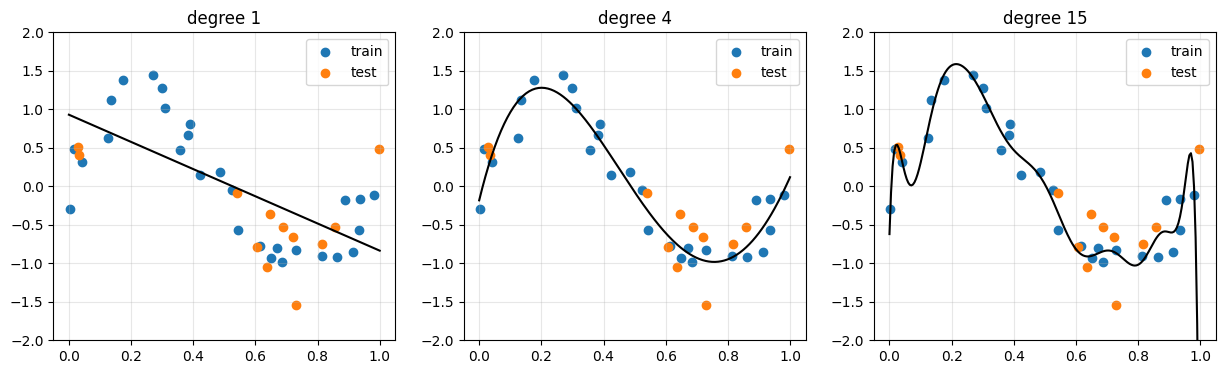

,degree,train MSE,test MSE
0,1,0.319,0.406
1,4,0.049,0.104
2,15,0.027,2.230


In [ ]:
rng = np.random.default_rng(0)
xs_p = np.sort(rng.uniform(0, 1, 40))
ys_p = np.sin(2 * np.pi * xs_p) + rng.normal(0, 0.25, 40)

Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(xs_p.reshape(-1, 1), ys_p, test_size=0.3, random_state=1)
grid_x = np.linspace(0, 1, 200).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
results = []
for ax, deg in zip(axes, [1, 4, 15]):
    poly = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LinearRegression()).fit(Xp_tr, yp_tr)
    tr = mean_squared_error(yp_tr, poly.predict(Xp_tr))
    te = mean_squared_error(yp_te, poly.predict(Xp_te))
    results.append({"degree": deg, "train MSE": tr, "test MSE": te})

    ax.scatter(Xp_tr, yp_tr, label="train", color="tab:blue")
    ax.scatter(Xp_te, yp_te, label="test", color="tab:orange")
    ax.plot(grid_x, poly.predict(grid_x), color="k")
    ax.set_ylim(-2, 2); ax.set_title(f"degree {deg}"); ax.legend()
plt.show()

pd.DataFrame(results).round(3)

| Degree | What you see | Diagnosis |
|---|---|---|
| 1 | A straight line that misses the curve; both errors are high | **Underfitting** |
| 4 | Follows the sine shape; both errors are low and close | **Good fit** |
| 15 | Wiggles through every training point; train error tiny, test error large | **Overfitting** |

**How to diagnose:** compare the train and test scores. A big gap means overfitting. Both low means underfitting.

**Remedies**
- Against overfitting: more data, a simpler model, regularization (Ridge or Lasso), or a larger K in KNN.
- Against underfitting: more features or a more flexible model, or a smaller K in KNN.

*Why this matters:* it ties every earlier section together. The test set (section 1), R² on train vs test (section 5) and the choice of K (section 7) are all about catching and avoiding this problem.

---
## Wrap-up

| Model | Predicts | Key idea | Watch out for |
|---|---|---|---|
| Linear regression | a number | weighted sum, weights learned by minimizing MSE | outliers, compare weights only on scaled features |
| Logistic regression | a category | linear score → sigmoid → probability → threshold | the 0.5 threshold is only a default |
| KNN | a category | majority vote of the K nearest points | scale features, choose K by cross-validation |

### Rules to keep
1. Identify the problem type (number or category) before choosing anything.
2. Split first, and fit scalers and other preprocessing on the training data only. A pipeline does this for you.
3. Never evaluate on training data.
4. Choose the metric by the cost of each kind of mistake.
5. Watch the gap between train and test scores.

### Final exercises
1. In section 1, change `test_size` to `0.5`. How do the metrics change, and why?
2. In section 3, add a new feature `size_per_room = size / rooms` and see whether R² improves.
3. In section 7, try `weights="distance"` and compare the CV accuracy.
4. In section 9, find a threshold where recall reaches 1.0 on the tumor model. What is the price in precision?
5. On a dataset of your own, run the full six-step pipeline and justify your choice of metric in one sentence.